In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import requests
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVC
import matplotlib.colors as mcolors


In [13]:
url_worldometer = 'https://www.worldometers.info/world-population/'
header = {"User-Agent" : "Mozilla/5.0"}
req_worldometer = requests.get(url_worldometer, headers=header)
tabel_worldometer = pd.read_html(req_worldometer.text)
df_populasi = tabel_worldometer[0]

print("Data Dari Website Worldometer")
display(df_populasi.head())

/tmp/ipykernel_1323/3112980106.py:4: FutureWarning: Passing literal html to 'read_html' is deprecated and will be removed in a future version. To read from a literal string, wrap it in a 'StringIO' object.
  tabel_worldometer = pd.read_html(req_worldometer.text)


Data Dari Website Worldometer


,Year (July 1),Population,Yearly % Change,Yearly Change,Median Age,Fertility Rate,Density (P/KmÂ²)
0,2026,8300678395,0.84%,69065325,31.1,2.23,56
1,2025,8231613070,0.85%,69640498,30.9,2.24,55
2,2024,8161972572,0.87%,70237642,30.6,2.25,55
3,2023,8091734930,0.88%,70327738,30.4,2.25,54
4,2022,8021407192,0.84%,66958801,30.1,2.27,54


In [14]:
url_scrape = 'https://www.scrapethissite.com/pages/forms/'
req_scrape = requests.get(url_scrape, headers=header)
tabel_scrape = pd.read_html(req_scrape.text)
df_hoki = tabel_scrape[0]

print("Data Dari Website Scraper")
display(df_hoki.head())

Data Dari Website Scraper


/tmp/ipykernel_1323/794798560.py:3: FutureWarning: Passing literal html to 'read_html' is deprecated and will be removed in a future version. To read from a literal string, wrap it in a 'StringIO' object.
  tabel_scrape = pd.read_html(req_scrape.text)


,Team Name,Year,Wins,Losses,OT Losses,Win %,Goals For (GF),Goals Against (GA),+ / -
0,Boston Bruins,1990,44,24,NaN,0.550,299,264,35
1,Buffalo Sabres,1990,31,30,NaN,0.388,292,278,14
2,Calgary Flames,1990,46,26,NaN,0.575,344,263,81
3,Chicago Blackhawks,1990,49,23,NaN,0.613,284,211,73
4,Detroit Red Wings,1990,34,38,NaN,0.425,273,298,-25


In [15]:
df_csv = pd.read_csv('Sleep_health_and_lifestyle_dataset.csv')

display(df_csv.head())

,Person ID,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Blood Pressure,Heart Rate,Daily Steps,Sleep Disorder
0,1,Male,27,Software Engineer,6.1,6,42,6,Overweight,126/83,77,4200,NaN
1,2,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
2,3,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
3,4,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea
4,5,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea


In [16]:

df_kotor = pd.concat([df_csv, df_csv.iloc[[0,1]]], ignore_index=True)

print(f"Jumlah Baris Awal : {len(df_csv)}, setelah kotor: {len(df_kotor)}")


Jumlah Baris Awal : 374, setelah kotor: 376


Text(0.5, 1.0, 'Peta Data Kosong')

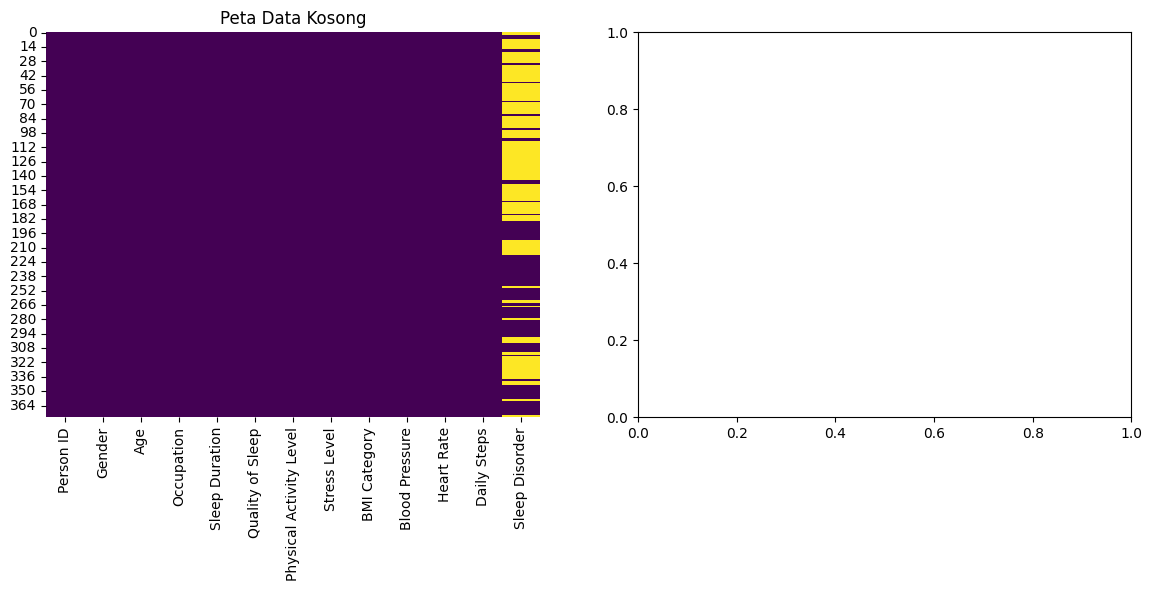

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(df_kotor.isnull(), cbar=False, cmap='viridis', ax=ax[0])
ax[0].set_title('Peta Data Kosong')

In [20]:
sns.boxplot(x=df_kotor['Sleep Duration'], ax=ax[1], color='skyblue')
ax[1].set_title('Boxplot Durasi Tidur')

plt.tight_layout()
plt.show()

<Figure size 640x480 with 0 Axes>

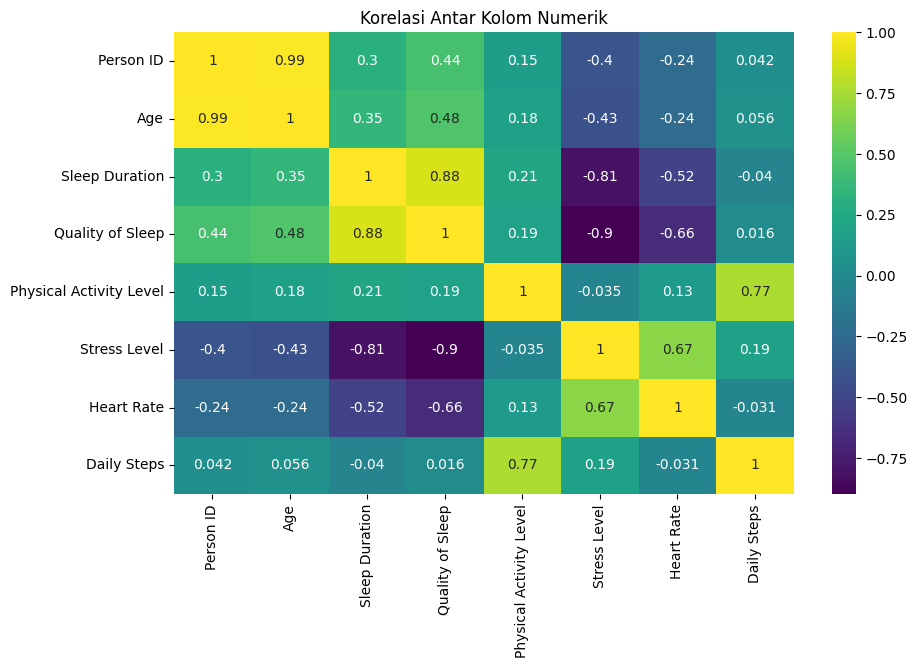

In [21]:
kolom_numerik = df_kotor.select_dtypes(include=[np.number])

plt.figure(figsize=(10, 6))
sns.heatmap(kolom_numerik.corr(), annot=True, cmap='viridis')
plt.title('Korelasi Antar Kolom Numerik')
plt.show()


In [27]:
diabetes = datasets.load_diabetes()
X_reg = diabetes.data[:,np.newaxis, 2]
Y_reg = diabetes.target

iris = datasets.load_iris()
X_clf = iris.data[:, :2]
Y_clf = iris.target

print("Dataset Berhasil Dimuat")

Dataset Berhasil Dimuat


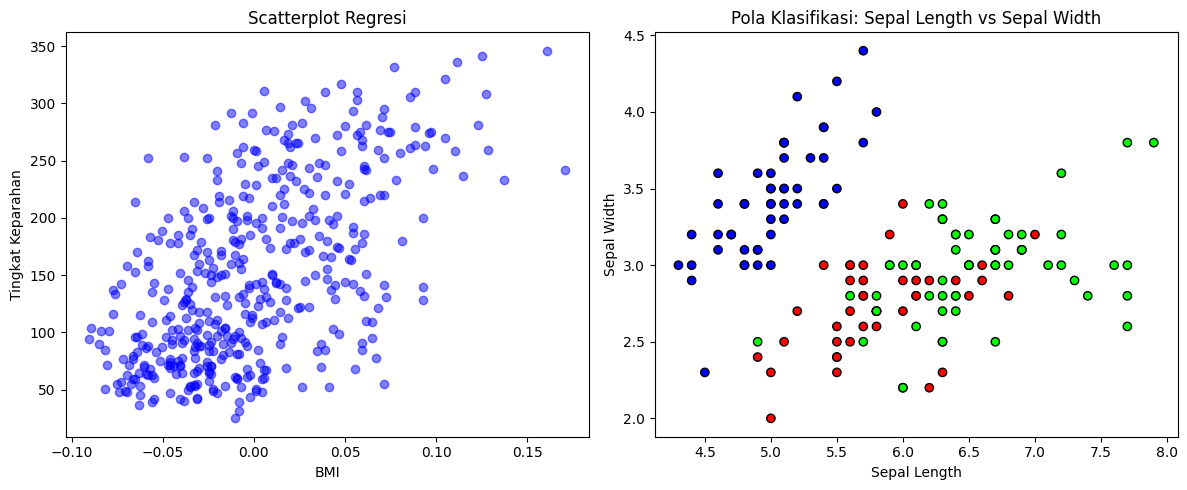

In [26]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ax[0].scatter(X_reg, Y_reg, color='blue', alpha=0.5)
ax[0].set_title('Scatterplot Regresi')
ax[0].set_xlabel('BMI')
ax[0].set_ylabel('Tingkat Keparahan')

scatter = ax[1].scatter(X_clf[:, 0], X_clf[:, 1], c=Y_clf, cmap='brg', edgecolor='k')
ax[1].set_title('Pola Klasifikasi: Sepal Length vs Sepal Width')
ax[1].set_xlabel('Sepal Length')
ax[1].set_ylabel('Sepal Width')

plt.tight_layout()
plt.show()

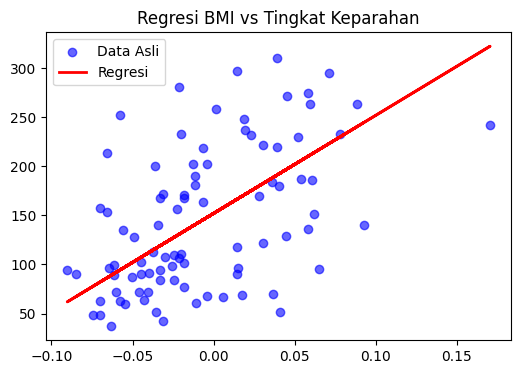

Tingkat Keparahan untuk BMI 22.49134948096886 adalah 22611.36314450562
Tingkat Keparahan untuk BMI 22.49134948096886 adalah 22611.36314450562


In [32]:
X_train_reg, X_test_reg, Y_train_reg, Y_test_reg = train_test_split(X_reg, Y_reg, test_size=0.2, random_state=42)

model_reg = LinearRegression()
model_reg.fit(X_train_reg, Y_train_reg)

Y_pred_reg = model_reg.predict(X_test_reg)

plt.figure(figsize=(6, 4))
plt.scatter(X_test_reg, Y_test_reg, color='blue', alpha=0.6, label='Data Asli')
plt.plot(X_test_reg, Y_pred_reg, color='red', linewidth=2, label='Regresi')
plt.title('Regresi BMI vs Tingkat Keparahan')
plt.legend()
plt.show()

berat_badan = 65
tinggi_badan = 170
bmi = berat_badan / ((tinggi_badan / 100) ** 2)
bmi_baru = np.array([[bmi]])
prediksi_diabetes = model_reg.predict(bmi_baru)
print(f"Tingkat Keparahan untuk BMI {bmi} adalah {prediksi_diabetes[0]}")

print(f"Tingkat Keparahan untuk BMI {bmi} adalah {prediksi_diabetes[0]}")